# 04 Renovation states and sections

This notebook compares the existing, standard and advanced states of one archetype,
shows what each renovation changes and draws the constructions as sections.

**Prerequisites:** `epsm_data` with the visualization extra for the drawings:
`python -m pip install -e ".[visualization]"` (adds matplotlib). Runs offline. U-values are
in W/(m² K).

Load the three states of the 1961–1975 multi-family archetype.

In [ ]:
from epsm_data import Catalogue

catalogue = Catalogue.load()
states = catalogue.renovation_states("mf_se02")
archetypes = {state: catalogue.get("mf_se02", state=state) for state in states}
print(states)

('existing', 'standard', 'advanced')


U-value per role in each state, and the change from existing to advanced.

In [ ]:
roles = list(archetypes["existing"].construction_set.elements)
print(f"{'role':<25}" + "".join(f"{state:>10}" for state in states) + "    change")
for role in roles:
    values = [archetypes[state].construction_set.elements[role].u_value for state in states]
    change = (values[-1] - values[0]) / values[0]
    print(f"{role.value:<25}" + "".join(f"{u:10.2f}" for u in values) + f"  {change:+8.0%}")

role                       existing  standard  advanced    change
BASEMENT_WALL                  3.17      3.17      0.67      -79%
EXT_WALL                       0.42      0.24      0.09      -80%
GROUND_FLOOR                   0.63      0.37      0.35      -45%
INTERMEDIATE_FLOOR             1.77      1.77      1.77       +0%
INT_WALL_NONLOADBEARING        0.60      0.60      0.60       +0%
TOP_FLOOR                      0.20      0.10      0.06      -71%
WINDOW                         2.22      0.90      0.76      -66%


Infiltration and ventilation change with the renovation too.

In [ ]:
for state, archetype in archetypes.items():
    envelope = archetype.envelope_performance
    print(f"{state:<9} infiltration {envelope.infiltration_l_s_m2} l/(s m² Atemp), "
          f"ventilation {archetype.hvac_template.template_id}")

existing  infiltration 0.2 l/(s m² Atemp), ventilation epsm.ventilation.F
standard  infiltration 0.1 l/(s m² Atemp), ventilation epsm.ventilation.F
advanced  infiltration 0.1 l/(s m² Atemp), ventilation epsm.ventilation.FTX_080


Each renovated role records in words what the renovation did.

In [ ]:
import textwrap

for state in ("standard", "advanced"):
    print(state)
    details = catalogue.nominal_metadata("mf_se02", state=state)["boundary_details"]
    for role, detail in details.items():
        if "renovation" in detail:
            print(f"  {role:<14}", textwrap.shorten(detail["renovation"], 90))

standard
  BASEMENT_WALL  retained baseline; excavation/accessibility not assumed
  EXT_WALL       TABULA exterior 50 mm insulation and 120 mm brick facing; all original components [...]
  GROUND_FLOOR   Original baseline retained; add 40 mm EPS on the warm side followed by a 50 mm [...]
  TOP_FLOOR      TABULA 200 mm loose-wool addition above retained original ceiling; nominal settled depth.
advanced
  BASEMENT_WALL  Retained concrete and plaster followed on the warm side by the TABULA 40 mm stone- [...]
  EXT_WALL       TABULA exterior 300 mm insulation and 120 mm brick facing; all original components [...]
  GROUND_FLOOR   Original baseline retained; add 45 mm EPS on the warm side followed by a 50 mm [...]
  TOP_FLOOR      TABULA 500 mm loose-wool addition above retained original ceiling; nominal settled depth.


The exterior wall layers, outside to inside. Renovation adds layers; it does not remove the original ones.

In [ ]:
for state, archetype in archetypes.items():
    wall = archetype.construction_set.elements["EXT_WALL"]
    names = [slot.layer.name for component in wall.components for slot in component.layers]
    print(f"{state:<9}", " | ".join(names))

existing  Brick + Mortar, 125 mm | Gypsum wind sheathing, 9.5 mm | Stone wool batts + Wooden stud, 95 mm | Plaster board, 9.5 mm | Gypsum board, 12.5 mm
standard  New brick facing, TABULA nominal 120 mm | Facade stone wool board, 50 mm | Brick + Mortar, 125 mm | Gypsum wind sheathing, 9.5 mm | Stone wool batts + Wooden stud, 95 mm | Plaster board, 9.5 mm | Gypsum board, 12.5 mm
advanced  New brick facing, TABULA nominal 120 mm | Facade stone wool board, 300 mm | Brick + Mortar, 125 mm | Gypsum wind sheathing, 9.5 mm | Stone wool batts + Wooden stud, 95 mm | Plaster board, 9.5 mm | Gypsum board, 12.5 mm


The drawings need matplotlib, from the `visualization` extra.

In [ ]:
import matplotlib.pyplot as plt

from epsm_data.plotting import plot_section_comparison, plot_sections

Boundary details add cavity geometry to the drawings without changing the thermal values.
Compare the exterior wall across the three states at one depth scale; added layers are tagged.

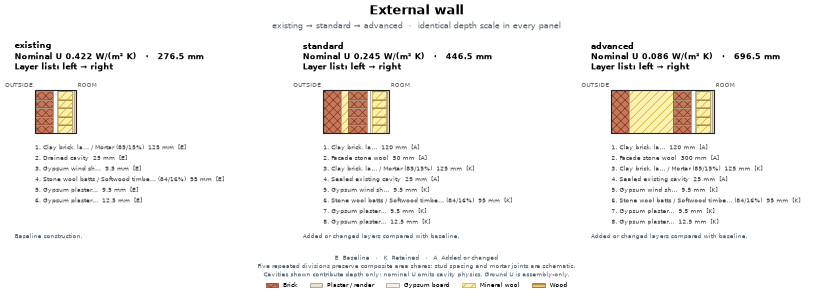

In [ ]:
boundaries = [catalogue.nominal_metadata("mf_se02", state=state)["boundary_details"] for state in states]
figure = plot_section_comparison(
    list(archetypes.values()), "EXT_WALL",
    boundary_details=boundaries, labels=list(states), dpi=50, show=False,
)
plt.show()

`plot_sections` draws every role of one archetype, here the advanced state.

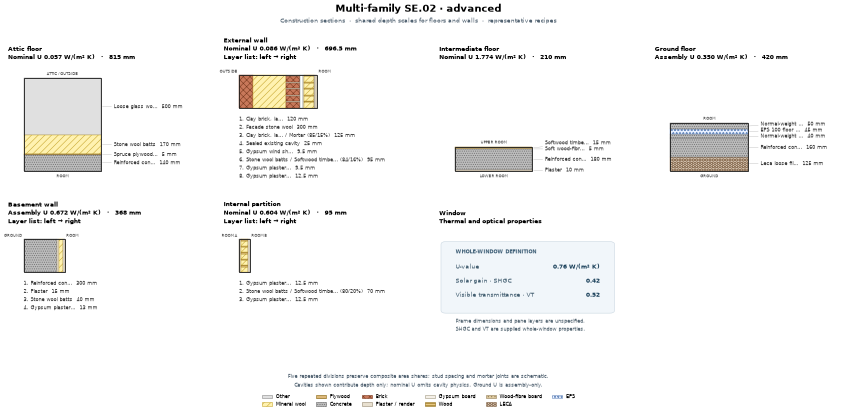

In [ ]:
figure = plot_sections(archetypes["advanced"], boundary_details=boundaries[-1], dpi=40, show=False)
plt.show()